# 07 Producción: aprendizaje profundo

Pregunta: qué red (LSTM o N-BEATS) y qué hiperparámetros ocupan la familia de aprendizaje profundo del tablero, cómo se comporta en un año que no vio, y cómo quedan los siete candidatos de las tres familias.

Decisión que sustenta: el ganador de aprendizaje profundo, su configuración estable entre semillas, el paquete que se sube al tablero, la tabla final de los siete candidatos y la propuesta de horizonte recomendado.

Sigue las secciones 2, 4 a 10 de METODOLOGIA_PRONOSTICO.md con el código del tablero (las clases Lstm y NBeats en Keras de pathologies/dengue/pronostico). Lee outputs/resultados/06_resultados.json para la tabla final y escribe outputs/resultados/07_resultados.json y outputs/RESULTADOS_PARA_INFORME.md.

## Decisiones que vienen de la investigación

Este notebook, como el 06, no vuelve a discutir el diseño del pronóstico: lo aplica. Las decisiones fijas y el notebook que las sustenta:

| Decisión heredada | Notebook de origen |
|---|---|
| Definición de caso (códigos 210 y 220) y depuración de los microdatos, que aplica el pipeline de limpieza del tablero | 01 |
| log1p(casos) como escala de trabajo de ARIMA, SARIMA, Prophet-AR y las redes, y como opción de los árboles | 03 |
| Entradas autorregresivas: rezagos de casos, con 1, 2, 4 y 8 semanas como punto de partida, y ventana de semanas para las redes, con 12 de partida | 03 |
| Estacionalidad anual de 52 semanas | 03 |
| Tres familias candidatas: estadística, aprendizaje automático y aprendizaje profundo | 03 |
| Evaluación multipaso de 1 a 6 semanas con origen móvil, porque a un paso los modelos no se distinguen | 03 |
| Sin variables climáticas: su aporte en el rango operativo no compensa el costo de mantener las series | 05 |

El agrupamiento de municipios (04) caracteriza el territorio y no entra en el pronóstico; la fuente climática por variable (02) no aplica porque el pronóstico no usa clima. Lo que se decide aquí, con esas decisiones fijas, es el modelo concreto de cada familia y sus hiperparámetros, en la serie que el tablero pronostica y con su propio código.

In [1]:
import getpass
import os
import sys
from pathlib import Path

# Modo rapido: 3 pruebas de Optuna por red, 1 semilla y 4 epocas (paciencia 2). Comprueba que
# el notebook corre de punta a punta; sus salidas van a subcarpetas _rapido y lee el 06 rapido.
MODO_RAPIDO = True
if "MODO_RAPIDO" in os.environ:
    MODO_RAPIDO = os.environ["MODO_RAPIDO"] == "1"

# Unica ruta al repositorio del tablero (o variable de entorno RUTA_TABLERO).
RUTA_TABLERO = os.environ.get("RUTA_TABLERO", r"C:\Users\edavi\PROYECTOS\public-health-surveillance-system")
USUARIO_TABLERO = os.environ.get("USUARIO_TABLERO", getpass.getuser())

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from dengue import experimentacion as ex

ex.preparar_entorno_determinista()
from dengue import produccion as pr

RUTA_TABLERO = pr.preparar_tablero(RUTA_TABLERO)
SALIDAS = ex.configurar_salidas("produccion_deep_learning", MODO_RAPIDO)
FIGURAS = ex.RegistroFiguras(SALIDAS, "07")
CRONO = ex.Cronometro()
CRONO.etapa("serie")
SEMILLAS = ex.SEMILLAS_REDES[:1] if MODO_RAPIDO else ex.SEMILLAS_REDES
print("Modo rapido:", MODO_RAPIDO, "| semillas:", SEMILLAS)
print("Tablero:", RUTA_TABLERO)
print("Figuras:", SALIDAS.figuras)

Modo rapido: True | semillas: [42]
Tablero: C:\Users\edavi\PROYECTOS\public-health-surveillance-system
Figuras: C:\Users\edavi\PROYECTOS\dengue-surveillance-magdalena\outputs\figures\produccion_deep_learning\_rapido


## 1 Serie del tablero y periodos 70/15/15

La misma serie del 06. Las redes dividen el 85 % de entrenamiento en entrenamiento (2007 a agosto de 2019, 70 %) y validación (agosto de 2019 a abril de 2022, 15 %): con fraccion_validacion = 0,15 / 0,85, la clase del tablero toma ese tramo final para la parada temprana, y Optuna compara las configuraciones en ese mismo bloque con el walk-forward. La prueba (abril de 2022 a diciembre de 2024) y 2025 son los mismos del 06. El determinismo de TensorFlow queda activado para todo el notebook.

In [2]:
import shutil
import tempfile
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
import optuna
import keras
import tensorflow as tf

from pathologies.dengue.pronostico import evaluacion, paquete
from pathologies.dengue.pronostico.manifest import ORIGEN_SUBIDO

warnings.filterwarnings('ignore')
ex.silenciar_registros()
ex.estilo_figuras()
ex.activar_determinismo_tensorflow()

SERIES = pr.cargar_series(RUTA_TABLERO)
SERIE = SERIES['serie']
SERIE_2024 = SERIES['serie_2024']
SEMANAS_2024 = SERIES['semanas_2024']
PERIODOS = pr.periodos(SERIE_2024)
N85, N70 = PERIODOS['fin_entrenamiento'], PERIODOS['fin_ajuste_redes']
SERIE_ENTRENAMIENTO = SERIE_2024.iloc[:N85].reset_index(drop=True)
print(PERIODOS['fechas'])
print('Dispositivos:', ex.describir_dispositivos())

C:\Users\edavi\PROYECTOS\dengue-surveillance-magdalena\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'inicio': '2006-12-31', 'inicio_validacion_redes': '2019-08-04', 'inicio_prueba': '2022-04-17', 'fin_prueba': '2024-12-22'}


Dispositivos: {'tensorflow_gpu': [], 'torch_cuda': True}


## 2 Búsqueda de hiperparámetros

Optuna con TPE y semilla fija. Cada configuración se entrena con 5 semillas (keras.utils.set_random_seed dentro de la clase y tf.config.experimental.enable_op_determinism) y su valor es el RMSE global (H1 a H6) medio de las semillas en el bloque de validación. La poda por mediana se aplica después de cada semilla: si el RMSE medio parcial de una configuración es peor que la mediana de las anteriores en ese mismo punto, se descarta sin entrenar las semillas restantes. Los espacios solo usan hiperparámetros de las clases del tablero.

LSTM (clase Lstm)

| Hiperparámetro | Rango | Escala | Motivo |
|---|---|---|---|
| ventana_semanas | 6 a 52 | entera | de mes y medio a un año de historia; la referencia es 12 |
| unidades: capas | 1 a 3 | entera | profundidad de la red (largo de la lista unidades) |
| unidades: por capa | 8 a 128 | logarítmica | ancho de cada capa |
| dropout | 0 a 0,5 | lineal | regularización |
| optimizador | adam o rmsprop | categórica | elección estructural |
| tasa de aprendizaje | 0,0001 a 0,01 | logarítmica | la clase pasa optimizador a compile(), que acepta la configuración serializada de Keras con learning_rate |
| batch_size | 8 a 64, potencias de 2 | logarítmica | tamaño de lote |

Fijos: activación tanh, pérdida MAE, hasta 200 épocas, paciencia 20 restaurando los mejores pesos, tasa a la mitad tras 10 épocas sin mejora, fraccion_validacion 0,15 / 0,85.

N-BEATS (clase NBeats, Keras, arquitectura genérica)

| Hiperparámetro | Rango | Escala | Motivo |
|---|---|---|---|
| ventana_semanas | 6 a 52 | entera | igual que la LSTM |
| num_pilas | 2 a 30 | logarítmica | el valor por defecto es 30; menos pilas abaratan el entrenamiento |
| bloques_por_pila | 1 a 2 | entera | número de bloques junto con las pilas |
| capas_por_bloque | 1 a 4 | entera | profundidad de cada bloque |
| ancho_capa | 32 a 256 | logarítmica | neuronas por capa |
| dropout | 0 a 0,5 | lineal | regularización |
| tasa_aprendizaje | 0,0001 a 0,01 | logarítmica | varía en dos órdenes de magnitud |
| batch_size | 8 a 64, potencias de 2 | logarítmica | tamaño de lote |

Fijos: dimensión de expansión 5, pérdida MSE, hasta 200 épocas, paciencia 20, fraccion_validacion 0,15 / 0,85.

Pruebas: 30 por red. Cada prueba entrena hasta 5 redes y es la más cara del proyecto; la poda corta pronto las configuraciones malas para que el presupuesto rinda en las buenas.

Elección estable (sección 6): entre las configuraciones completas cuyo RMSE medio queda a menos de un 5 % del mejor, la de menor desviación entre semillas. No se usan ensambles.

In [3]:
CRONO.etapa('busqueda')
N_PRUEBAS = pr.PRUEBAS_RAPIDO if MODO_RAPIDO else pr.PRUEBAS
ESTUDIOS, CANDIDATOS = {}, {}


def buscar_red(clave, espacio):
    clase = pr.clase_modelo(clave)
    estudio = ex.crear_estudio(f'07_{clave}', ex.podador_por_semilla())
    objetivo = pr.objetivo_red(clase, lambda trial: espacio(trial, MODO_RAPIDO), SERIE_ENTRENAMIENTO, SEMILLAS)
    estudio.optimize(objetivo, n_trials=N_PRUEBAS[clave], gc_after_trial=True)
    historial = ex.guardar_historial(estudio, SALIDAS, f'07_{clave}')
    completas = [{'numero': t.number, 'rmse_media': t.user_attrs['rmse_media'], 'rmse_sd': t.user_attrs['rmse_sd'],
                  'mae': t.user_attrs['mae'], 'hiperparametros': t.user_attrs['hiperparametros']}
                 for t in estudio.trials if t.state == optuna.trial.TrialState.COMPLETE]
    eleccion = ex.elegir_configuracion_estable(completas)
    elegida = eleccion['elegida']
    ESTUDIOS[clave] = estudio
    CANDIDATOS[clave] = {
        'nombre': clase.nombre, 'familia': clase.familia,
        'hiperparametros': {**clase.hiperparametros_por_defecto, **elegida['hiperparametros']},
        'optuna': {**ex.resumen_estudio(estudio), 'historial': historial},
        'validacion': {'rmse_media': elegida['rmse_media'], 'rmse_sd': elegida['rmse_sd'], 'mae': elegida['mae'],
                       'prueba_optuna': elegida['numero'], 'mejor_rmse_media': eleccion['mejor_rmse_media'],
                       'configuraciones_a_menos_de_5_por_ciento': eleccion['cercanas']},
    }
    tabla = pd.DataFrame([{k: v for k, v in p.items() if k != 'hiperparametros'} for p in completas])
    display(tabla.sort_values('rmse_media').head(10).round(3))
    print(f"{clase.nombre}: configuracion {elegida['numero']} (RMSE medio {elegida['rmse_media']:.3f}, "
          f"desviacion {elegida['rmse_sd']:.3f}); a menos de un 5 %: {eleccion['cercanas']}")
    print('  hiperparametros:', elegida['hiperparametros'])


buscar_red('lstm', pr.espacio_lstm)

,numero,rmse_media,rmse_sd,mae
0,0,15.624,0.0,11.458
2,2,16.665,0.0,12.183
1,1,18.763,0.0,14.250


LSTM: configuracion 0 (RMSE medio 15.624, desviacion 0.000); a menos de un 5 %: [0]
  hiperparametros: {'ventana_semanas': 8, 'unidades': [112, 60], 'dropout': 0.4330880728874676, 'optimizador': {'class_name': 'Adam', 'config': {'learning_rate': 0.00020511104188433984}}, 'batch_size': 32, 'paciencia_tasa_aprendizaje': 2, 'epocas_maximas': 4, 'paciencia': 2, 'fraccion_validacion': 0.17647058823529413}


In [4]:
buscar_red('nbeats', pr.espacio_nbeats)

,numero,rmse_media,rmse_sd,mae
2,2,42.164,0.0,20.432
1,1,79.397,0.0,34.909
0,0,705.158,0.0,123.898


N-BEATS: configuracion 2 (RMSE medio 42.164, desviacion 0.000); a menos de un 5 %: [2]
  hiperparametros: {'ventana_semanas': 20, 'num_pilas': 7, 'bloques_por_pila': 1, 'capas_por_bloque': 2, 'ancho_capa': 114, 'dropout': 0.06974693032602092, 'tasa_aprendizaje': 0.0003839629299804173, 'batch_size': 16, 'epocas_maximas': 4, 'paciencia': 2, 'fraccion_validacion': 0.17647058823529413}


## 3 Prueba con 5 semillas y ganador de la familia

Cada red, con su configuración estable, pasa por evaluacion.evaluar_en_prueba del tablero con cada una de las 5 semillas. Criterio (sección 7): el RMSE global (H1 a H6) medio de las semillas; a menos de un 2 %, el menor MAE global; si el MAE también queda a menos de un 2 %, la menor desviación entre semillas.

In [5]:
CRONO.etapa('prueba')
REGISTROS_PRUEBA = {}
for clave, candidato in CANDIDATOS.items():
    clase = pr.clase_modelo(clave)
    lista, partes = [], []
    for semilla in SEMILLAS:
        keras.backend.clear_session()
        resultado = pr.evaluar_en_prueba(clase, {**candidato['hiperparametros'], 'semilla': semilla}, SERIE_2024)
        lista.append(resultado['metricas'])
        partes.append(resultado['registros'].assign(semilla=semilla))
    REGISTROS_PRUEBA[clave] = pd.concat(partes, ignore_index=True)
    REGISTROS_PRUEBA[clave].to_csv(SALIDAS.registros / f'07_{clave}_prueba.csv', index=False, date_format='%Y-%m-%d')
    candidato['prueba'] = ex.resumir_semillas(lista)
    candidato['prueba_por_semilla'] = lista
    g = candidato['prueba']['global']['modelo']
    print(f"{candidato['nombre']}: RMSE global {g['RMSE']:.3f} (sd {g['RMSE_sd']:.3f}) | MAE {g['MAE']:.3f}")

metricas = {k: {'RMSE': v['prueba']['global']['modelo']['RMSE'], 'MAE': v['prueba']['global']['modelo']['MAE'],
                'RMSE_sd': v['prueba']['global']['modelo']['RMSE_sd']} for k, v in CANDIDATOS.items()}
eleccion = ex.elegir_ganador(metricas)
GANADOR = eleccion['ganador']
print(f"Gana {CANDIDATOS[GANADOR]['nombre']} ({eleccion['criterio']})")
PERSISTENCIA_PRUEBA = {'global': lista[0]['global']['persistencia'],
                       'por_horizonte': {h: v['persistencia'] for h, v in lista[0]['por_horizonte'].items()}}

LSTM: RMSE global 25.123 (sd 0.000) | MAE 16.961


N-BEATS: RMSE global 35.132 (sd 0.000) | MAE 21.374
Gana LSTM (RMSE global)


## 4 Prueba final en 2025 con 5 semillas

El ganador se entrena con 2007 a 2024 (modelo.entrenar) con cada semilla y pronostica desde cada semana de origen las 6 siguientes (modelo.pronosticar_trayectorias); se conservan los registros cuya semana objetivo es de 2025. Ningún resultado de esta prueba cambia una decisión.

In [6]:
CRONO.etapa('prueba_final_2025')
lista, partes = [], []
for semilla in SEMILLAS:
    keras.backend.clear_session()
    resultado = pr.prueba_final(pr.clase_modelo(GANADOR), {**CANDIDATOS[GANADOR]['hiperparametros'], 'semilla': semilla},
                                SERIE, SEMANAS_2024)
    lista.append(resultado['metricas'])
    partes.append(resultado['registros'].assign(semilla=semilla))
REGISTROS_2025 = pd.concat(partes, ignore_index=True)
REGISTROS_2025.to_csv(SALIDAS.registros / f'07_{GANADOR}_2025.csv', index=False, date_format='%Y-%m-%d')
PRUEBA_FINAL = {'resumen': ex.resumir_semillas(lista), 'por_semilla': lista}
display(ex.tabla_por_horizonte(PRUEBA_FINAL['resumen']).round(3))

,H,RMSE,MAE,MAPE,R2
0,1,54.541,30.908,27.731,0.285
1,2,55.791,31.660,28.371,0.252
2,3,58.004,33.028,29.524,0.192
3,4,60.747,34.791,31.014,0.113
4,5,63.596,36.653,32.678,0.028
5,6,66.212,38.451,34.436,-0.053
6,global,59.959,34.248,30.626,0.136


## 5 Exportación al tablero

Un paquete para el ganador, con paquete.entrenar_evaluar_y_guardar sobre todo 2007-2025, la primera semilla (42) y el determinismo activado; se empaqueta con paquete.exportar_zip en outputs/paquetes y se revisa una copia descomprimida con paquete.revisar_paquete, la misma revisión del tablero al subirlo.

In [7]:
CRONO.etapa('exportacion')
keras.backend.clear_session()
hp_exportacion = {**CANDIDATOS[GANADOR]['hiperparametros'], 'semilla': SEMILLAS[0]}
trabajo = Path(tempfile.mkdtemp(prefix=f'paquete_{GANADOR}_'))
manifest = paquete.entrenar_evaluar_y_guardar(GANADOR, hp_exportacion, SERIE, trabajo / GANADOR, USUARIO_TABLERO,
                                              ORIGEN_SUBIDO)
ruta_zip = paquete.exportar_zip(trabajo / GANADOR, SALIDAS.paquetes / f'{GANADOR}.zip')
with zipfile.ZipFile(ruta_zip) as archivo_zip:
    archivo_zip.extractall(trabajo / 'revision')
revisado = paquete.revisar_paquete(trabajo / 'revision', SERIE, USUARIO_TABLERO)
(SALIDAS.paquetes / f'{GANADOR}_manifest.json').write_text((trabajo / GANADOR / 'manifest.json').read_text(encoding='utf-8'),
                                                         encoding='utf-8')
shutil.rmtree(trabajo, ignore_errors=True)
PAQUETE = {'zip': SALIDAS.relativa(ruta_zip), 'manifest': SALIDAS.relativa(SALIDAS.paquetes / f'{GANADOR}_manifest.json'),
           'revision_tablero': 'aceptado', 'compatibilidad': revisado['compatibilidad'], 'semilla': SEMILLAS[0],
           'rango': manifest['rango'], 'prueba': manifest['prueba'], 'metricas_prueba': manifest['metricas_prueba'],
           'detalles_entrenamiento': manifest.get('detalles_entrenamiento')}
print(f'{GANADOR}.zip aceptado por revisar_paquete | compatibilidad: {revisado["compatibilidad"]}')

lstm.zip aceptado por revisar_paquete | compatibilidad: {'tensorflow': {'exportado': '2.21.0', 'instalado': '2.21.0', 'estado': 'igual'}, 'keras': {'exportado': '3.14.1', 'instalado': '3.14.1', 'estado': 'igual'}}


## 6 Importancia de los hiperparámetros del ganador

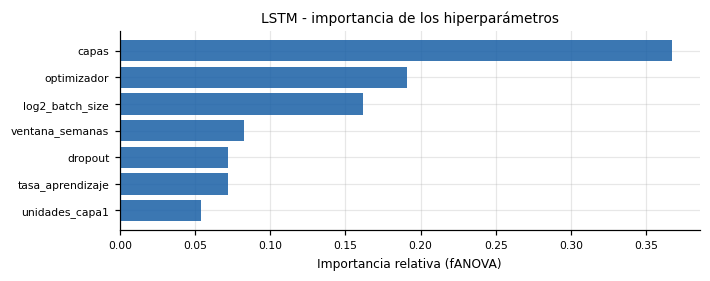

In [8]:
fig, IMPORTANCIAS = ex.figura_importancias(ESTUDIOS[GANADOR], f"{CANDIDATOS[GANADOR]['nombre']} - importancia de los hiperparámetros")
FIGURAS.guardar(fig, f'importancia_hiperparametros_{GANADOR}.png',
                f"Importancia de los hiperparámetros (fANOVA de Optuna) del ganador {CANDIDATOS[GANADOR]['nombre']}")
plt.show()

## 7 Tabla final de los siete candidatos

Métricas de la prueba (abril de 2022 a diciembre de 2024) de los siete candidatos: los cinco del 06 (06_resultados.json) y las dos redes de este notebook (media de las semillas). El ganador de cada familia sale del criterio de la sección 7; la razón contra la persistencia es un control.

In [9]:
CRONO.etapa('tabla_final')
R06 = ex.leer_json(SALIDAS.resultados / '06_resultados.json')
if R06['modo_rapido'] != MODO_RAPIDO:
    raise ValueError('06_resultados.json es de otro modo de ejecucion.')
if R06['periodos']['fechas']['inicio_prueba'] != PERIODOS['fechas']['inicio_prueba']:
    raise ValueError('La prueba del 06 no coincide con la de este notebook.')

TODOS = {**R06['candidatos'], **ex._a_json(CANDIDATOS)}
GANADORES = {fam: g['clave'] for fam, g in R06['ganadores'].items()}
GANADORES['aprendizaje_profundo'] = GANADOR
NOMBRES_FAMILIA = {'estadistico': 'Estadística', 'aprendizaje_automatico': 'Aprendizaje automático',
                   'aprendizaje_profundo': 'Aprendizaje profundo'}

filas = []
for clave, cand in TODOS.items():
    g = cand['prueba']['global']
    filas.append({'Modelo': cand['nombre'], 'clave': clave, 'Familia': NOMBRES_FAMILIA[cand['familia']],
                  'RMSE': g['modelo']['RMSE'], 'RMSE sd': g['modelo'].get('RMSE_sd'), 'MAE': g['modelo']['MAE'],
                  'MAPE': g['modelo']['MAPE'], 'R2': g['modelo']['R2'],
                  'RMSE / persistencia': g['modelo']['RMSE'] / g['persistencia']['RMSE'],
                  'Ganador': clave in GANADORES.values()})
p = PERSISTENCIA_PRUEBA['global']
filas.append({'Modelo': 'Persistencia', 'clave': 'persistencia', 'Familia': 'control', 'RMSE': p['RMSE'], 'MAE': p['MAE'],
              'MAPE': p['MAPE'], 'R2': p['R2'], 'RMSE / persistencia': 1.0, 'Ganador': False})
TABLA_FINAL = pd.DataFrame(filas)
display(TABLA_FINAL.drop(columns='clave').round(3))

filas = []
for clave, cand in TODOS.items():
    for h, bloque in cand['prueba']['por_horizonte'].items():
        filas.append({'Modelo': cand['nombre'], 'clave': clave, 'familia': cand['familia'], 'H': int(h),
                      **{m: bloque['modelo'][m] for m in ('RMSE', 'MAE', 'MAPE', 'R2')},
                      'RMSE sd': bloque['modelo'].get('RMSE_sd'), 'RMSE persistencia': bloque['persistencia']['RMSE']})
for h, bloque in PERSISTENCIA_PRUEBA['por_horizonte'].items():
    filas.append({'Modelo': 'Persistencia', 'clave': 'persistencia', 'familia': 'persistencia', 'H': int(h),
                  **{m: bloque[m] for m in ('RMSE', 'MAE', 'MAPE', 'R2')}, 'RMSE persistencia': bloque['RMSE']})
TABLA_HORIZONTES = pd.DataFrame(filas)
display(TABLA_HORIZONTES.pivot(index='Modelo', columns='H', values='RMSE').round(2))

FINAL_2025 = {clave: R06['prueba_final_2025'][clave] for clave in (GANADORES['estadistico'], GANADORES['aprendizaje_automatico'])}
FINAL_2025[GANADOR] = PRUEBA_FINAL['resumen']

,Modelo,Familia,RMSE,RMSE sd,MAE,MAPE,R2,RMSE / persistencia,Ganador
0,ARIMA,Estadística,18.228,NaN,12.946,31.260,0.706,1.006,False
1,SARIMA,Estadística,18.128,NaN,12.815,30.649,0.709,1.000,False
2,Prophet-AR,Estadística,16.962,NaN,11.830,28.147,0.745,0.936,True
3,XGBoost,Aprendizaje automático,21.575,NaN,14.656,31.062,0.588,1.191,False
4,LightGBM,Aprendizaje automático,20.019,NaN,13.740,30.706,0.645,1.105,True
5,LSTM,Aprendizaje profundo,25.123,0.0,16.961,33.687,0.441,1.386,True
6,N-BEATS,Aprendizaje profundo,35.132,0.0,21.374,48.004,-0.092,1.939,False
7,Persistencia,control,18.120,NaN,12.963,31.842,0.709,1.000,False


H,1,2,3,4,5,6
Modelo,,,,,,
ARIMA,11.17,13.74,16.68,19.20,21.39,24.00
LSTM,22.31,22.91,23.97,25.35,26.93,28.68
LightGBM,11.81,14.90,18.72,21.47,23.76,25.84
N-BEATS,19.51,20.96,28.38,38.52,40.50,51.54
Persistencia,11.19,13.89,16.44,19.31,21.12,23.72
Prophet-AR,12.00,14.14,16.13,17.46,19.23,21.15
SARIMA,11.47,13.96,16.50,19.03,21.19,23.70
XGBoost,14.41,17.73,20.62,21.98,25.05,27.11


## 8 Figuras para el informe

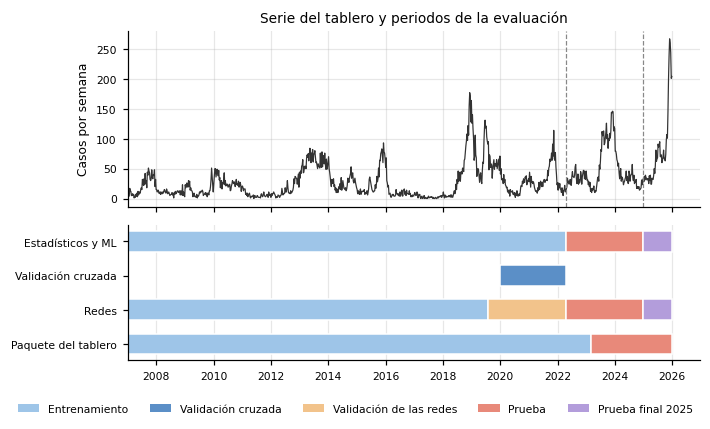

In [10]:
CRONO.etapa('figuras')
f = pd.to_datetime(SERIE['fecha_semana'])
f24 = pd.to_datetime(SERIE_2024['fecha_semana'])
inicio, f70, f85 = f24.iloc[0], f24.iloc[N70], f24.iloc[N85]
f2025, fin = f.iloc[SEMANAS_2024], f.iloc[-1] + pd.Timedelta(weeks=1)
n_total = len(SERIE)
f_export = f.iloc[n_total - int(round(n_total * 0.15))]
cortes = R06['validacion_cruzada']

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(6.5, 3.8), sharex=True, gridspec_kw={'height_ratios': [1.3, 1]})
ax0.plot(f, SERIE['casos'], color='#333333', lw=0.8)
ax0.set_ylabel('Casos por semana')
ax0.set_title('Serie del tablero y periodos de la evaluación')
for x in (f85, f2025):
    ax0.axvline(x, color='#888888', ls='--', lw=0.8)
colores = {'Entrenamiento': '#9ec5e8', 'Validación de las redes': '#f2c38b', 'Prueba': '#e8897a',
           'Prueba final 2025': '#b39ddb', 'Validación cruzada': '#5b8fc7', 'Evaluación del paquete': '#e8897a'}
filas = [
    ('Estadísticos y ML', [(inicio, f85, 'Entrenamiento'), (f85, f2025, 'Prueba'), (f2025, fin, 'Prueba final 2025')]),
    ('Validación cruzada', [(pd.Timestamp(k['inicio_fecha']), pd.Timestamp(k['fin_fecha']) + pd.Timedelta(weeks=1), 'Validación cruzada') for k in cortes]),
    ('Redes', [(inicio, f70, 'Entrenamiento'), (f70, f85, 'Validación de las redes'), (f85, f2025, 'Prueba'), (f2025, fin, 'Prueba final 2025')]),
    ('Paquete del tablero', [(inicio, f_export, 'Entrenamiento'), (f_export, fin, 'Evaluación del paquete')]),
]
for y, (etiqueta, tramos) in enumerate(reversed(filas)):
    for desde, hasta, tipo in tramos:
        ax1.barh(y, (hasta - desde).days, left=desde, height=0.6, color=colores[tipo], edgecolor='white')
ax1.set_yticks(range(len(filas)))
ax1.set_yticklabels([e for e, _ in reversed(filas)])
ax1.grid(axis='y', alpha=0)
ax1.xaxis.set_major_locator(mdates.YearLocator(2))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
leyenda = [Patch(facecolor=colores[k], label=k) for k in ('Entrenamiento', 'Validación cruzada', 'Validación de las redes', 'Prueba', 'Prueba final 2025')]
fig.legend(handles=leyenda, loc='lower center', ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.05, 1, 1))
FIGURAS.guardar(fig, 'linea_de_tiempo_periodos.png', 'Línea de tiempo de los periodos: entrenamiento 85 %, cortes de validación cruzada, validación de las redes (70/15/15), prueba, prueba final 2025 y la partición 85/15 con que el tablero evalúa el paquete exportado')
plt.show()

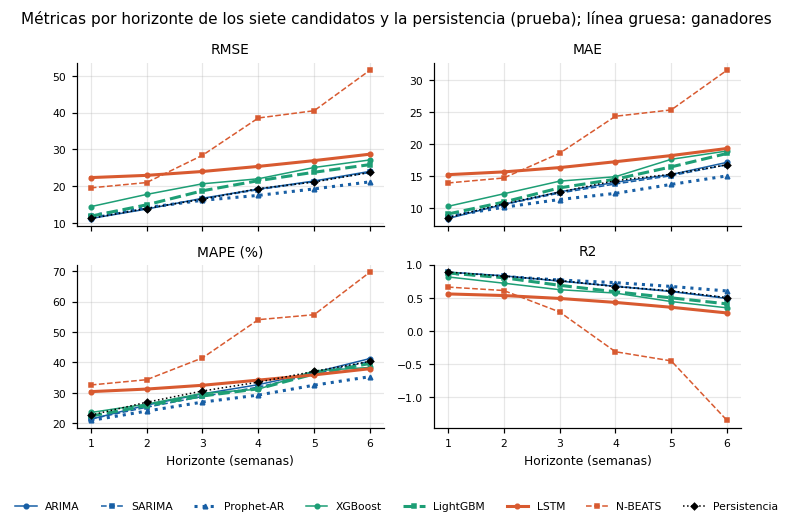

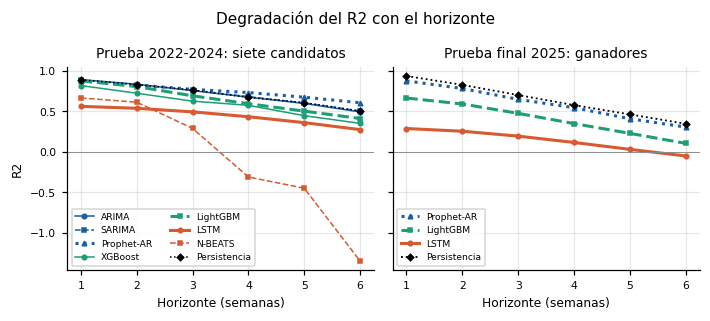

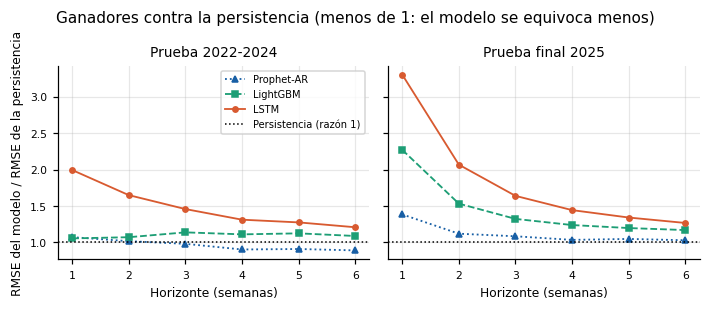

In [11]:
ESTILO = {
    'arima': ('#185FA5', '-', 'o'), 'sarima': ('#185FA5', '--', 's'), 'prophet_ar': ('#185FA5', ':', '^'),
    'xgboost': ('#1D9E75', '-', 'o'), 'lightgbm': ('#1D9E75', '--', 's'),
    'lstm': ('#D85A30', '-', 'o'), 'nbeats': ('#D85A30', '--', 's'), 'persistencia': ('black', ':', 'D'),
}
fig, axes = plt.subplots(2, 2, figsize=(6.5, 4.6), sharex=True)
for ax, metrica in zip(axes.flat, ['RMSE', 'MAE', 'MAPE', 'R2']):
    for clave, (color, ls, marcador) in ESTILO.items():
        parte = TABLA_HORIZONTES[TABLA_HORIZONTES['clave'] == clave].sort_values('H')
        if parte.empty:
            continue
        ancho = 2.0 if clave in GANADORES.values() else 1.0
        ax.plot(parte['H'], parte[metrica], color=color, ls=ls, marker=marcador, markersize=3, lw=ancho,
                label=parte['Modelo'].iloc[0])
    ax.set_title(metrica + (' (%)' if metrica == 'MAPE' else ''))
    ax.set_xticks(ex.HORIZONTES)
for ax in axes[1]:
    ax.set_xlabel('Horizonte (semanas)')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=8, frameon=False, bbox_to_anchor=(0.5, -0.03))
fig.suptitle('Métricas por horizonte de los siete candidatos y la persistencia (prueba); línea gruesa: ganadores')
fig.tight_layout(rect=(0, 0.05, 1, 1))
FIGURAS.guardar(fig, 'metricas_por_horizonte_candidatos.png', 'RMSE, MAE, MAPE y R2 por horizonte de los siete candidatos y la persistencia en la prueba; las redes con la media de las semillas')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(6.5, 2.9), sharey=True)
for clave, (color, ls, marcador) in ESTILO.items():
    parte = TABLA_HORIZONTES[TABLA_HORIZONTES['clave'] == clave].sort_values('H')
    if not parte.empty:
        axes[0].plot(parte['H'], parte['R2'], color=color, ls=ls, marker=marcador, markersize=3,
                     lw=2.0 if clave in GANADORES.values() else 1.0, label=parte['Modelo'].iloc[0])
for clave in GANADORES.values():
    color, ls, marcador = ESTILO[clave]
    r2 = [FINAL_2025[clave]['por_horizonte'][str(h)]['modelo']['R2'] for h in ex.HORIZONTES]
    axes[1].plot(ex.HORIZONTES, r2, color=color, ls=ls, marker=marcador, markersize=3, lw=2.0, label=TODOS[clave]['nombre'])
p25 = [FINAL_2025[GANADOR]['por_horizonte'][str(h)]['persistencia']['R2'] for h in ex.HORIZONTES]
axes[1].plot(ex.HORIZONTES, p25, color='black', ls=':', marker='D', markersize=3, label='Persistencia')
axes[0].set_title('Prueba 2022-2024: siete candidatos')
axes[1].set_title('Prueba final 2025: ganadores')
for ax in axes:
    ax.set_xlabel('Horizonte (semanas)')
    ax.set_xticks(ex.HORIZONTES)
    ax.axhline(0, color='#888888', lw=0.6)
axes[0].set_ylabel('R2')
axes[0].legend(fontsize=6, ncol=2)
axes[1].legend(fontsize=6)
fig.suptitle('Degradación del R2 con el horizonte')
fig.tight_layout()
FIGURAS.guardar(fig, 'degradacion_r2_horizonte.png', 'R2 según el horizonte: los siete candidatos en la prueba y los tres ganadores en 2025, con la persistencia')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(6.5, 2.8), sharey=True)
for ax, (titulo, fuente) in zip(axes, [('Prueba 2022-2024', 'prueba'), ('Prueba final 2025', '2025')]):
    for clave in GANADORES.values():
        color, ls, marcador = ESTILO[clave]
        bloques = TODOS[clave]['prueba']['por_horizonte'] if fuente == 'prueba' else FINAL_2025[clave]['por_horizonte']
        razon = [bloques[str(h)]['modelo']['RMSE'] / bloques[str(h)]['persistencia']['RMSE'] for h in ex.HORIZONTES]
        ax.plot(ex.HORIZONTES, razon, color=color, ls=ls, marker=marcador, markersize=3.5, label=TODOS[clave]['nombre'])
    ax.axhline(1, color='black', ls=':', lw=1, label='Persistencia (razón 1)')
    ax.set_title(titulo)
    ax.set_xlabel('Horizonte (semanas)')
    ax.set_xticks(ex.HORIZONTES)
axes[0].set_ylabel('RMSE del modelo / RMSE de la persistencia')
axes[0].legend(fontsize=6.5)
fig.suptitle('Ganadores contra la persistencia (menos de 1: el modelo se equivoca menos)')
fig.tight_layout()
FIGURAS.guardar(fig, 'ganadores_contra_persistencia.png', 'Razón entre el RMSE de cada ganador y el de la persistencia por horizonte, en la prueba y en 2025')
plt.show()

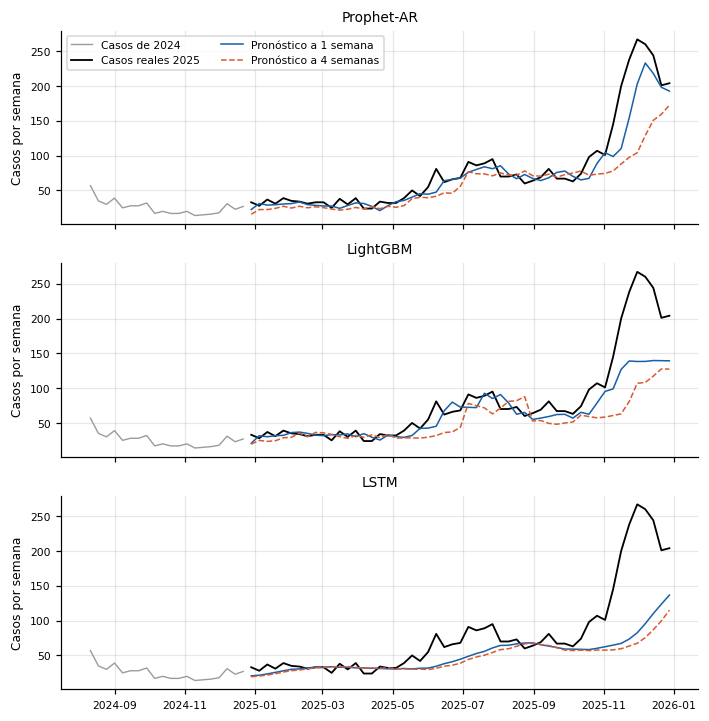

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(6.5, 6.6), sharex=True)
contexto = SERIE.iloc[SEMANAS_2024 - 20:SEMANAS_2024]
orden = [GANADORES['estadistico'], GANADORES['aprendizaje_automatico'], GANADOR]
for ax, clave in zip(axes, orden):
    if clave == GANADOR:
        registros = REGISTROS_2025[REGISTROS_2025['semilla'] == SEMILLAS[0]]
        banda = REGISTROS_2025.groupby(['horizonte_semanas', 'fecha_objetivo'])['pronostico_modelo'].agg(['min', 'max']).reset_index()
    else:
        registros = pd.read_csv(SALIDAS.registros / f'06_{clave}_2025.csv', parse_dates=['fecha_origen', 'fecha_objetivo'])
        banda = None
    ax.plot(contexto['fecha_semana'], contexto['casos'], color='#9a9a9a', lw=0.9, label='Casos de 2024')
    reales = registros[registros['horizonte_semanas'] == 1].sort_values('fecha_objetivo')
    ax.plot(reales['fecha_objetivo'], reales['casos_reales'], color='black', lw=1.2, label='Casos reales 2025')
    for h, color, ls in ((1, '#185FA5', '-'), (4, '#D85A30', '--')):
        parte = registros[registros['horizonte_semanas'] == h].sort_values('fecha_objetivo')
        ax.plot(parte['fecha_objetivo'], parte['pronostico_modelo'], color=color, ls=ls, lw=1.0,
                label=f'Pronóstico a {h} semana' + ('s' if h > 1 else ''))
        if banda is not None and len(SEMILLAS) > 1:
            b = banda[banda['horizonte_semanas'] == h].sort_values('fecha_objetivo')
            ax.fill_between(b['fecha_objetivo'], b['min'], b['max'], color=color, alpha=0.15, lw=0)
    sufijo = f' (semilla {SEMILLAS[0]}; banda: rango de las {len(SEMILLAS)} semillas)' if clave == GANADOR and len(SEMILLAS) > 1 else ''
    ax.set_title(f"{TODOS[clave]['nombre']}{sufijo}")
    ax.set_ylabel('Casos por semana')
axes[0].legend(ncol=2, loc='upper left')
fig.tight_layout()
FIGURAS.guardar(fig, 'prueba_final_2025_ganadores.png', 'Casos reales de 2025 contra los pronósticos a 1 y 4 semanas de los tres ganadores (la red con la semilla exportada y el rango de sus semillas)')
plt.show()

## 9 Horizonte recomendado (propuesta)

Sección 9 de la metodología: el horizonte máximo en el que el error sigue siendo útil y los ganadores superan a la persistencia, con los resultados de la prueba y de la prueba final. Se propone el mayor horizonte h tal que, en todos los horizontes de 1 a h, los tres ganadores tienen un RMSE menor que la persistencia en la prueba y en 2025, y un R² de al menos 0,5 en la prueba (el pronóstico explica al menos la mitad de la variación semanal). La propuesta queda como dato en 07_resultados.json; el valor que usa el tablero es HORIZONTE_RECOMENDADO_SEMANAS en su configuracion.py, que este notebook no modifica.

In [13]:
UMBRAL_R2_UTIL = 0.5
filas = []
for h in ex.HORIZONTES:
    fila = {'H': h}
    cumple = True
    for clave in orden:
        prueba = TODOS[clave]['prueba']['por_horizonte'][str(h)]
        final = FINAL_2025[clave]['por_horizonte'][str(h)]
        supera_prueba = prueba['modelo']['RMSE'] < prueba['persistencia']['RMSE']
        supera_2025 = final['modelo']['RMSE'] < final['persistencia']['RMSE']
        util = prueba['modelo']['R2'] is not None and prueba['modelo']['R2'] >= UMBRAL_R2_UTIL
        fila[f"{TODOS[clave]['nombre']}: supera persistencia (prueba / 2025)"] = f'{supera_prueba} / {supera_2025}'
        fila[f"{TODOS[clave]['nombre']}: R2 prueba"] = round(prueba['modelo']['R2'], 3)
        cumple = cumple and supera_prueba and supera_2025 and util
    fila['cumple'] = cumple
    filas.append(fila)
TABLA_HORIZONTE = pd.DataFrame(filas)
display(TABLA_HORIZONTE)
horizonte = 0
for fila in filas:
    if not fila['cumple']:
        break
    horizonte = fila['H']
from pathologies.dengue.pronostico.configuracion import HORIZONTE_RECOMENDADO_SEMANAS
HORIZONTE_PROPUESTO = {
    'horizonte_semanas': horizonte if horizonte > 0 else None,
    'regla': ('mayor h tal que en todos los horizontes de 1 a h los tres ganadores tienen RMSE menor que la persistencia '
              f'en la prueba y en 2025 y R2 >= {UMBRAL_R2_UTIL} en la prueba'),
    'valor_actual_tablero': HORIZONTE_RECOMENDADO_SEMANAS,
    'detalle': TABLA_HORIZONTE.to_dict('records'),
}
print('Horizonte propuesto:', HORIZONTE_PROPUESTO['horizonte_semanas'], '| valor actual en el tablero:', HORIZONTE_RECOMENDADO_SEMANAS)

,H,Prophet-AR: supera persistencia (prueba / 2025),Prophet-AR: R2 prueba,LightGBM: supera persistencia (prueba / 2025),LightGBM: R2 prueba,LSTM: supera persistencia (prueba / 2025),LSTM: R2 prueba,cumple
0,1,False / False,0.872,False / False,0.876,False / False,0.560,False
1,2,False / False,0.823,False / False,0.804,False / False,0.535,False
2,3,True / False,0.770,False / False,0.690,False / False,0.492,False
3,4,True / False,0.730,False / False,0.592,False / False,0.431,False
4,5,True / False,0.673,False / False,0.500,False / False,0.358,False
5,6,True / False,0.604,False / False,0.409,False / False,0.272,False


Horizonte propuesto: None | valor actual en el tablero: 4


## 10 Resultados

outputs/resultados/07_resultados.json: las dos redes (búsqueda, configuración estable, prueba con 5 semillas), el ganador y su criterio, la prueba final 2025, el paquete exportado, la tabla final de los siete candidatos y el horizonte propuesto.

In [14]:
from datetime import datetime, timezone

CRONO.etapa('resultados')
RESULTADOS_07 = {
    'notebook': '07_produccion_deep_learning',
    'modo_rapido': MODO_RAPIDO,
    'fecha': datetime.now(timezone.utc).isoformat(),
    'serie': 'tablero: construir_serie_semanal_departamental sobre dengue_consolidado.parquet',
    'periodos': PERIODOS,
    'horizontes': ex.HORIZONTES,
    'semillas': SEMILLAS,
    'pruebas_optuna': N_PRUEBAS,
    'candidatos': CANDIDATOS,
    'persistencia_prueba': PERSISTENCIA_PRUEBA,
    'ganador': {'clave': GANADOR, **eleccion},
    'prueba_final_2025': PRUEBA_FINAL,
    'paquete': PAQUETE,
    'importancias_hiperparametros': IMPORTANCIAS,
    'tabla_final': TABLA_FINAL.drop(columns='clave').to_dict('records'),
    'tabla_horizontes': TABLA_HORIZONTES.to_dict('records'),
    'ganadores_por_familia': GANADORES,
    'horizonte_recomendado_propuesto': HORIZONTE_PROPUESTO,
    'figuras': FIGURAS.figuras,
    'tiempos': CRONO.resumen(),
    'dispositivos': ex.describir_dispositivos(),
    'versiones': ex.versiones_librerias(['tensorflow', 'keras', 'optuna', 'numpy', 'pandas']),
}
ruta = ex.guardar_json(RESULTADOS_07, SALIDAS.resultados / '07_resultados.json')
print('Guardado:', ruta)
print('Tiempo total (s):', RESULTADOS_07['tiempos']['total_segundos'])

Guardado: C:\Users\edavi\PROYECTOS\dengue-surveillance-magdalena\outputs\resultados\_rapido\07_resultados.json
Tiempo total (s): 278.6


## 11 RESULTADOS_PARA_INFORME.md

Se genera desde los JSON de los notebooks 03, 05, 06 y 07 (no a mano): la lista de figuras con su ruta y lo que muestra, y las tablas de métricas listas para el informe.

In [15]:
from dengue import informe

ruta_informe = informe.escribir(SALIDAS)
print('Guardado:', ruta_informe)

Guardado: C:\Users\edavi\PROYECTOS\dengue-surveillance-magdalena\outputs\_rapido\RESULTADOS_PARA_INFORME.md
